In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


In [2]:

# Paso 2: Cargar los datos del Titanic

archivo = "Reto excel semana 7.xlsx"

df = pd.read_excel(
    archivo,
    sheet_name="Titanic",
    usecols="A:D"
)

# Mostrar los primeros 10 pasajeros
df.head(10)


,Survived,Pclass,Sex,Age
0,0,3,0,22.0
1,1,1,1,38.0
2,1,3,1,26.0
3,1,1,1,35.0
4,0,3,0,35.0
5,0,1,0,54.0
6,0,3,0,2.0
7,1,3,1,27.0
8,1,2,1,14.0
9,1,3,1,4.0


In [3]:

# Paso 3: Explorar la estructura de los datos

print("DIMENSIONES DEL DATAFRAME:")
print(df.shape)

print("\nINFORMACIÓN GENERAL:")
df.info()

print("\nVALORES FALTANTES:")
print(df.isnull().sum())


DIMENSIONES DEL DATAFRAME:
(714, 4)

INFORMACIÓN GENERAL:
<class 'pandas.DataFrame'>
RangeIndex: 714 entries, 0 to 713
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  714 non-null    int64  
 1   Pclass    714 non-null    int64  
 2   Sex       714 non-null    int64  
 3   Age       714 non-null    float64
dtypes: float64(1), int64(3)
memory usage: 22.4 KB

VALORES FALTANTES:
Survived    0
Pclass      0
Sex         0
Age         0
dtype: int64


In [4]:

# Paso 4: Estadísticas descriptivas

print("RESUMEN ESTADÍSTICO DEL TITANIC")

df.describe()


RESUMEN ESTADÍSTICO DEL TITANIC


,Survived,Pclass,Sex,Age
count,714.000000,714.000000,714.000000,714.000000
mean,0.406162,2.236695,0.365546,29.699118
std,0.491460,0.838250,0.481921,14.526497
min,0.000000,1.000000,0.000000,0.420000
25%,0.000000,1.000000,0.000000,20.125000
50%,0.000000,2.000000,0.000000,28.000000
75%,1.000000,3.000000,1.000000,38.000000
max,1.000000,3.000000,1.000000,80.000000


In [5]:

# Paso 5: Separar variables independientes y dependiente

X = df[["Survived", "Pclass", "Sex"]]

y = df["Age"]

print("VARIABLES INDEPENDIENTES (X):")
print(X.head())

print("\nVARIABLE DEPENDIENTE (Y):")
print(y.head())


VARIABLES INDEPENDIENTES (X):
   Survived  Pclass  Sex
0         0       3    0
1         1       1    1
2         1       3    1
3         1       1    1
4         0       3    0

VARIABLE DEPENDIENTE (Y):
0    22.0
1    38.0
2    26.0
3    35.0
4    35.0
Name: Age, dtype: float64


In [6]:

# Paso 6: Entrenar la regresión lineal múltiple

modelo = LinearRegression()

modelo.fit(X, y)

print("INTERCEPTO:")
print(modelo.intercept_)

print("\nCOEFICIENTES:")
print(modelo.coef_)


INTERCEPTO:
50.39722957464966

COEFICIENTES:
[-6.33860614 -7.86510834 -1.45470541]


In [7]:

# Paso 7: Construir la ecuación de regresión

intercepto = modelo.intercept_
coeficientes = modelo.coef_

print("ECUACIÓN DE REGRESIÓN LINEAL MÚLTIPLE:\n")

print(
    f"Edad estimada = {intercepto:.4f} "
    f"+ ({coeficientes[0]:.4f} × Survived) "
    f"+ ({coeficientes[1]:.4f} × Pclass) "
    f"+ ({coeficientes[2]:.4f} × Sex)"
)


ECUACIÓN DE REGRESIÓN LINEAL MÚLTIPLE:

Edad estimada = 50.3972 + (-6.3386 × Survived) + (-7.8651 × Pclass) + (-1.4547 × Sex)


In [8]:

# Paso 8: Pronosticar la edad de un pasajero

# Características del pasajero
supervivencia = 1
clase = 2
sexo = 0

# Calcular la edad utilizando nuestra ecuación
edad_estimada = (
    intercepto
    + coeficientes[0] * supervivencia
    + coeficientes[1] * clase
    + coeficientes[2] * sexo
)

print(f"Edad estimada del pasajero: {edad_estimada:.2f} años")


Edad estimada del pasajero: 28.33 años


In [9]:

# Paso 9: Verificar el pronóstico con Scikit-learn

nuevo_pasajero = pd.DataFrame({
    "Survived": [1],
    "Pclass": [2],
    "Sex": [0]
})

prediccion = modelo.predict(nuevo_pasajero)

print(f"Edad calculada manualmente: {edad_estimada:.2f} años")
print(f"Edad calculada por el modelo: {prediccion[0]:.2f} años")

print(f"¿Coinciden los resultados? {np.isclose(edad_estimada, prediccion[0])}")


Edad calculada manualmente: 28.33 años
Edad calculada por el modelo: 28.33 años
¿Coinciden los resultados? True


In [10]:

# Paso 10: Evaluar el modelo de regresión lineal múltiple

# Pronosticar las edades de los pasajeros
edades_predichas = modelo.predict(X)

# Calcular las métricas de evaluación
mae = mean_absolute_error(y, edades_predichas)
r2 = r2_score(y, edades_predichas)

# Mostrar los resultados
print("EVALUACIÓN DEL MODELO")
print(f"Error absoluto medio (MAE): {mae:.2f} años")
print(f"Coeficiente de determinación (R²): {r2:.4f}")


EVALUACIÓN DEL MODELO
Error absoluto medio (MAE): 10.30 años
Coeficiente de determinación (R²): 0.1886


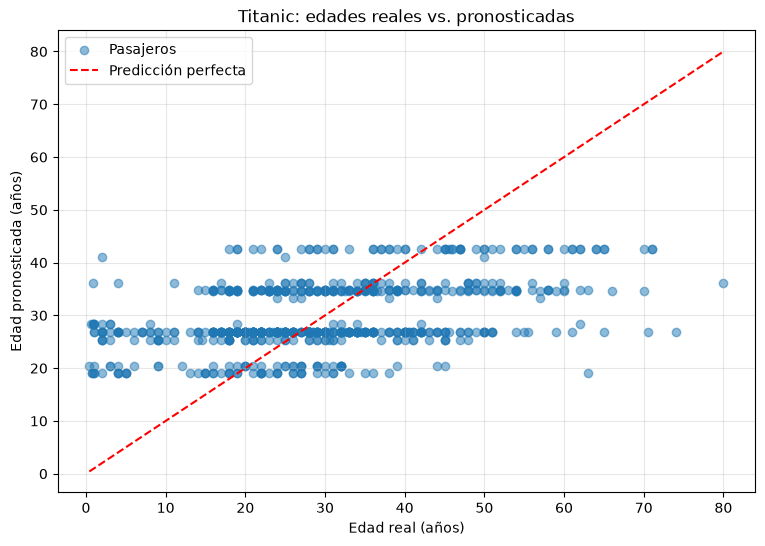

In [11]:

# Paso 11: Comparar edades reales y pronosticadas

plt.figure(figsize=(9, 6))

plt.scatter(
    y,
    edades_predichas,
    alpha=0.5,
    label="Pasajeros"
)

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    "r--",
    label="Predicción perfecta"
)

plt.xlabel("Edad real (años)")
plt.ylabel("Edad pronosticada (años)")
plt.title("Titanic: edades reales vs. pronosticadas")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


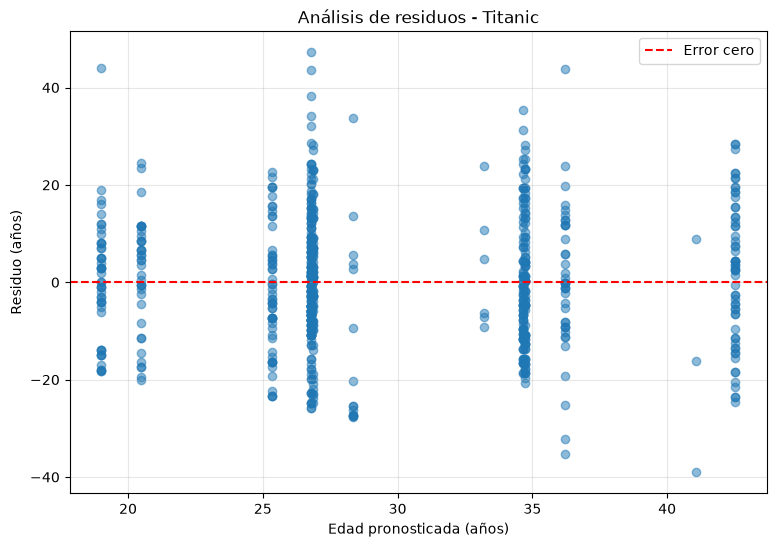

In [12]:

# Paso 12: Calcular y visualizar los residuos

residuos = y - edades_predichas

plt.figure(figsize=(9, 6))

plt.scatter(
    edades_predichas,
    residuos,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Error cero"
)

plt.xlabel("Edad pronosticada (años)")
plt.ylabel("Residuo (años)")
plt.title("Análisis de residuos - Titanic")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [13]:

# Paso 13: Crear tabla de resultados

resultados = df.copy()

# Agregar las predicciones
resultados["Edad_Pronosticada"] = edades_predichas

# Calcular los errores
resultados["Residuo"] = (
    resultados["Age"] - resultados["Edad_Pronosticada"]
)

resultados["Error_Absoluto"] = resultados["Residuo"].abs()

# Mostrar los primeros 10 registros
display(resultados.head(10))


,Survived,Pclass,Sex,Age,Edad_Pronosticada,Residuo,Error_Absoluto
0,0,3,0,22.0,26.801905,-4.801905,4.801905
1,1,1,1,38.0,34.738810,3.261190,3.261190
2,1,3,1,26.0,19.008593,6.991407,6.991407
3,1,1,1,35.0,34.738810,0.261190,0.261190
4,0,3,0,35.0,26.801905,8.198095,8.198095
5,0,1,0,54.0,42.532121,11.467879,11.467879
6,0,3,0,2.0,26.801905,-24.801905,24.801905
7,1,3,1,27.0,19.008593,7.991407,7.991407
8,1,2,1,14.0,26.873701,-12.873701,12.873701
9,1,3,1,4.0,19.008593,-15.008593,15.008593


In [14]:

# Paso 14: Exportar los resultados a Excel

nombre_archivo = "Reto_Semana_07_Resultados.xlsx"

resultados.to_excel(
    nombre_archivo,
    sheet_name="Predicciones_Titanic",
    index=False
)

print("Archivo Excel generado correctamente:")
print(nombre_archivo)

print(f"Total de registros exportados: {len(resultados)}")


Archivo Excel generado correctamente:
Reto_Semana_07_Resultados.xlsx
Total de registros exportados: 714


In [15]:

# Paso 15: Crear resumen y actualizar el Excel

resumen_modelo = pd.DataFrame({
    "Concepto": [
        "Intercepto",
        "Coeficiente Survived",
        "Coeficiente Pclass",
        "Coeficiente Sex",
        "Error absoluto medio (MAE)",
        "Coeficiente de determinación (R²)"
    ],
    "Valor": [
        modelo.intercept_,
        modelo.coef_[0],
        modelo.coef_[1],
        modelo.coef_[2],
        mae,
        r2
    ]
})

# Guardar las predicciones y el resumen
# en dos hojas del mismo archivo Excel

with pd.ExcelWriter(nombre_archivo) as escritor:
    resultados.to_excel(
        escritor,
        sheet_name="Predicciones_Titanic",
        index=False
    )

    resumen_modelo.to_excel(
        escritor,
        sheet_name="Resumen_Modelo",
        index=False
    )

print("Archivo Excel actualizado correctamente.")

display(resumen_modelo)


Archivo Excel actualizado correctamente.


,Concepto,Valor
0,Intercepto,50.397230
1,Coeficiente Survived,-6.338606
2,Coeficiente Pclass,-7.865108
3,Coeficiente Sex,-1.454705
4,Error absoluto medio (MAE),10.302181
5,Coeficiente de determinación (R²),0.188635
